<class 'pandas.DataFrame'>
DatetimeIndex: 1984 entries, 2019-01-02 to 2026-11-20
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   NVDA       1984 non-null   float64
 1   TLT        1984 non-null   float64
 2   XLI        1984 non-null   float64
 3   10Y_Yield  1984 non-null   float64
dtypes: float64(4)
memory usage: 77.5 KB


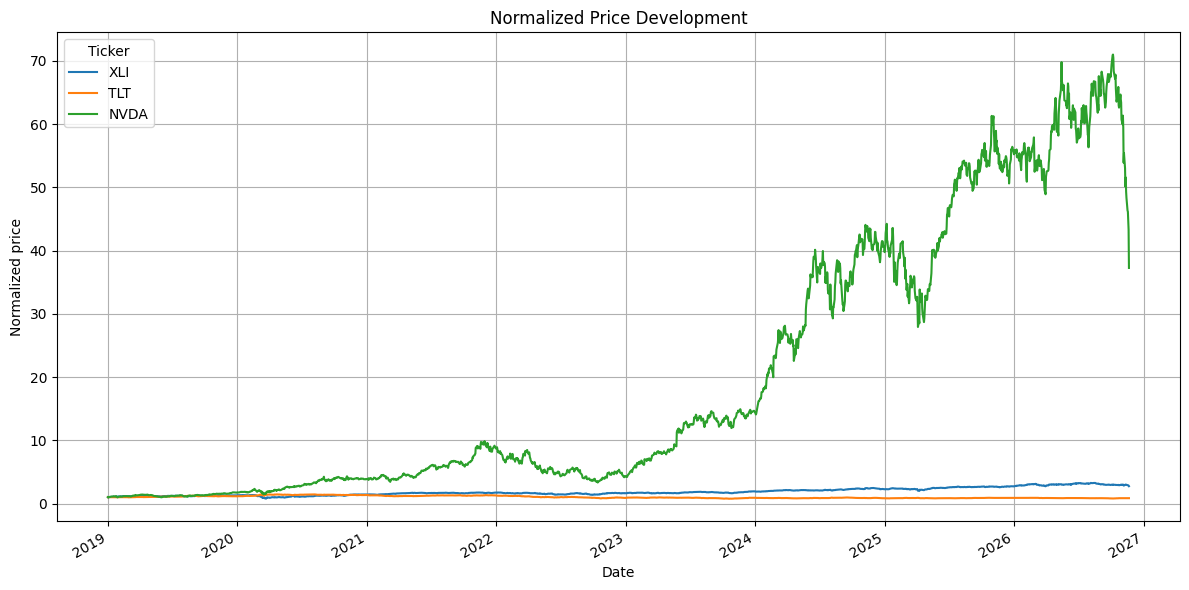

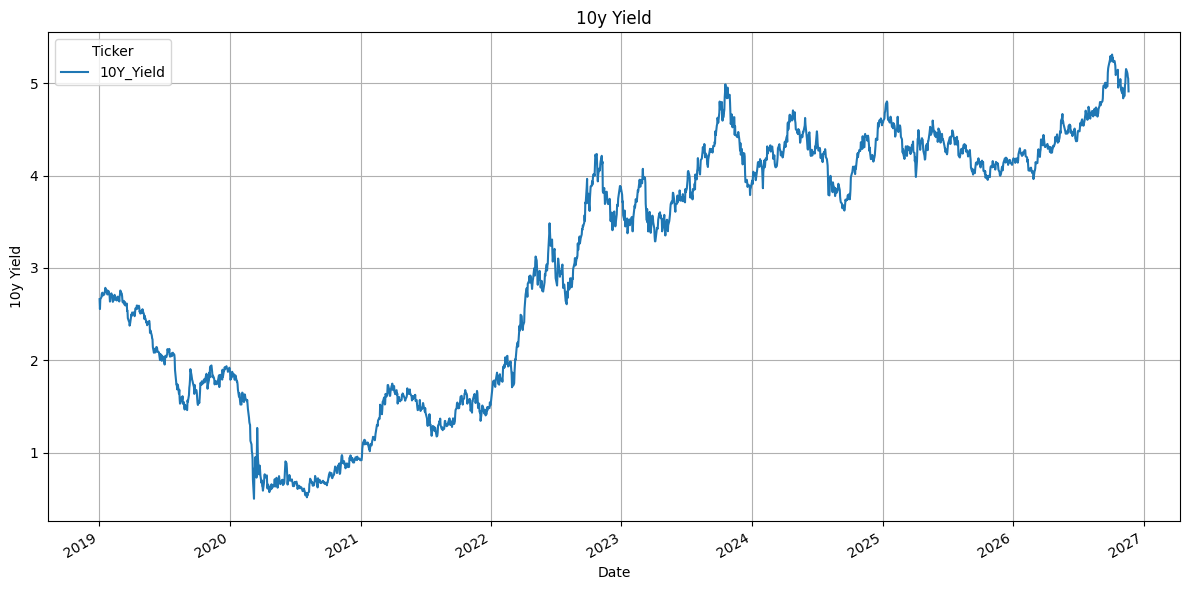

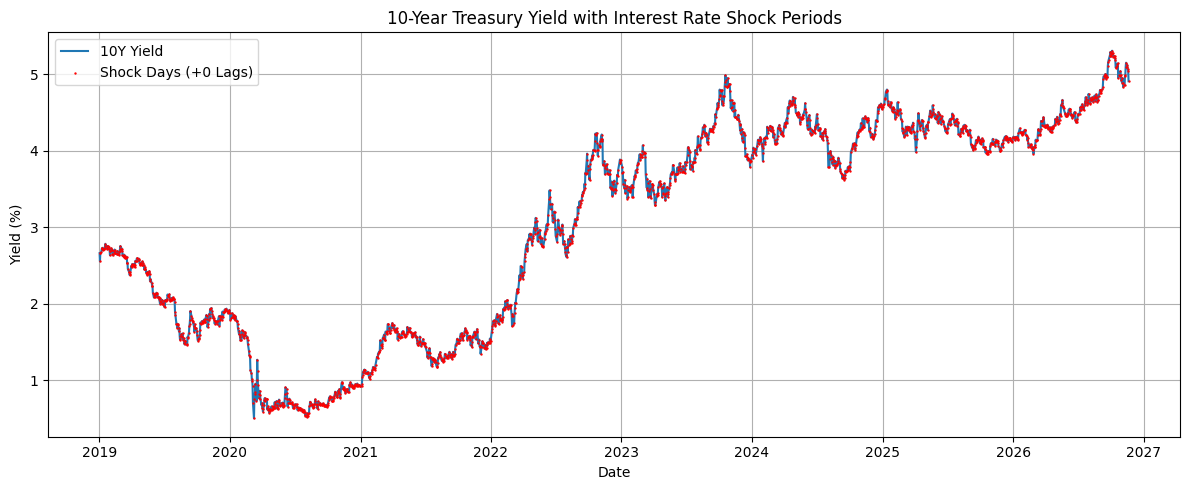

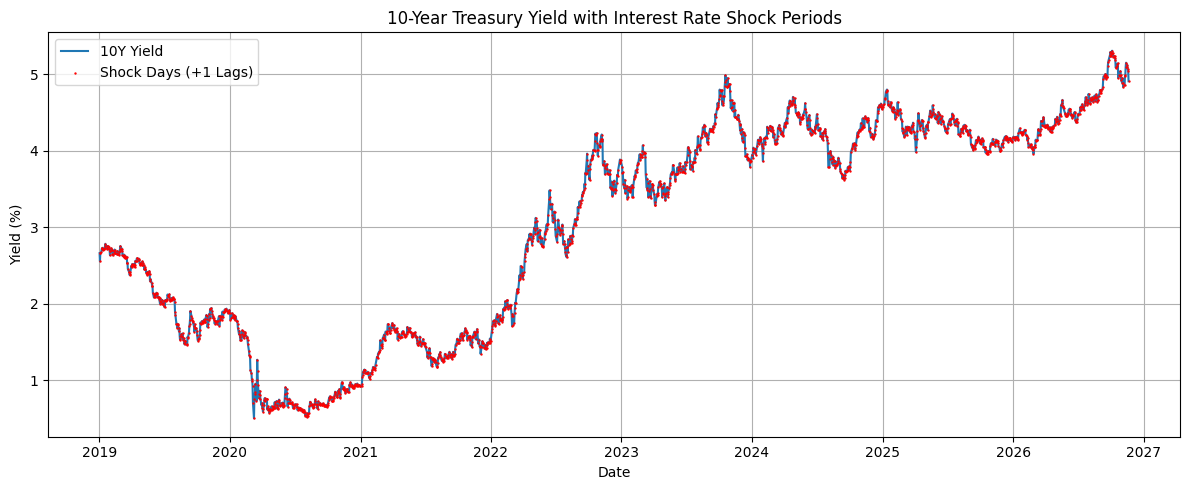

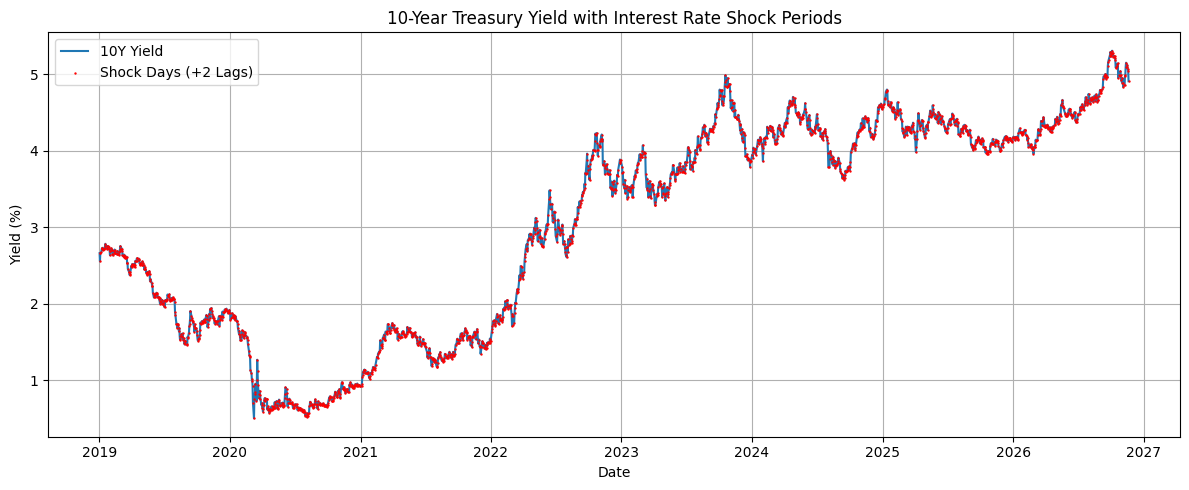

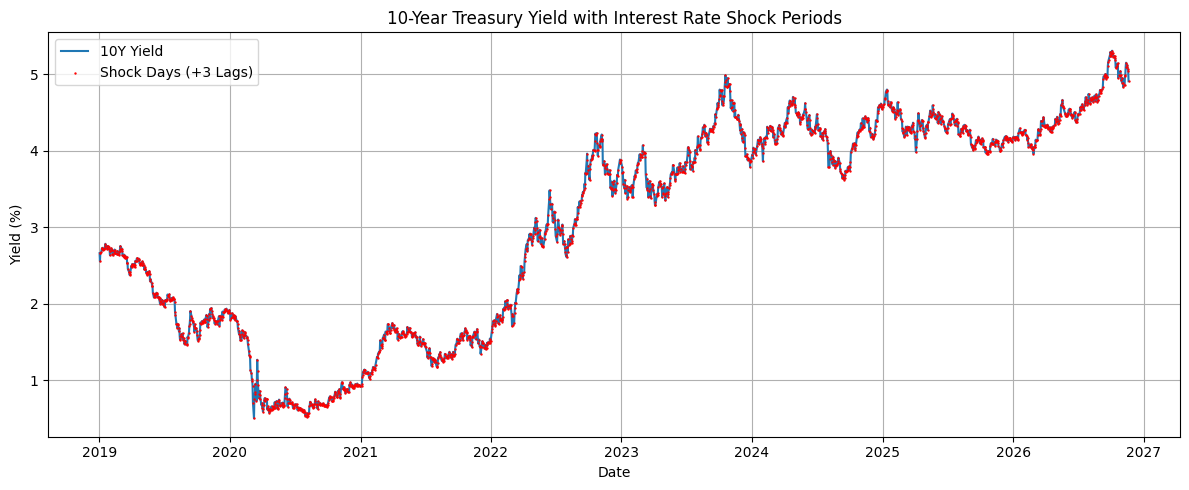

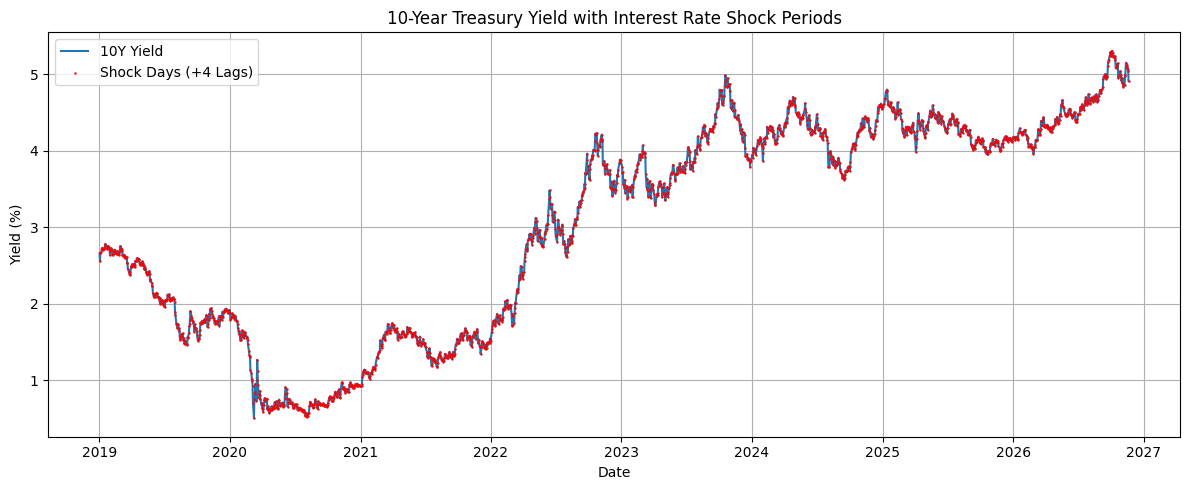

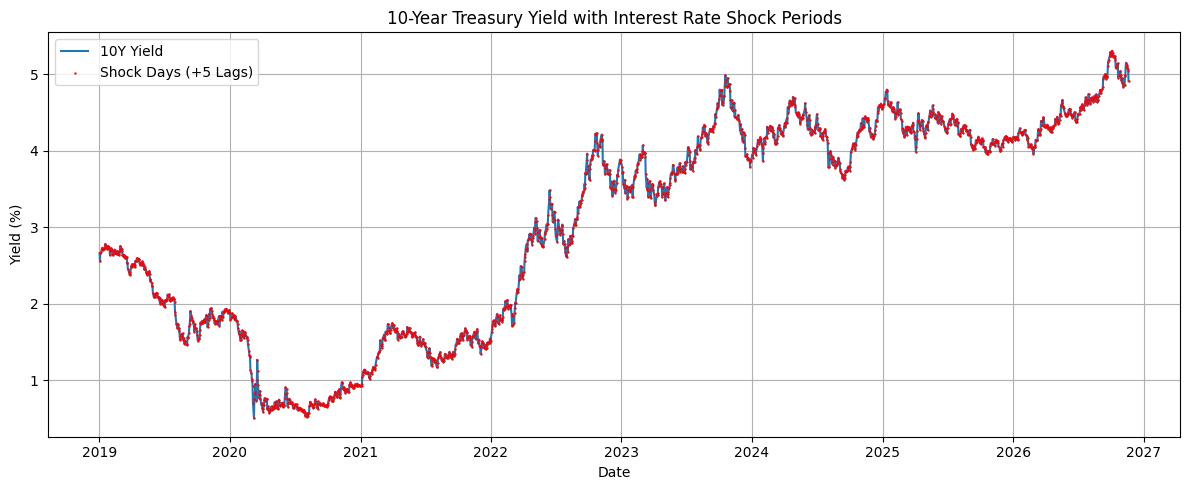

2019-01-02 00:00:00 2026-10-30 00:00:00 1969


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import sys
from pathlib import Path

sys.path.append(str(Path("../src").resolve()))

import dataloader
import mathematical_framework
import plotting

import importlib
importlib.reload(dataloader)

data = dataloader.load_all_project_data()
portfolio_assets, yield_10y = dataloader.split_project_data(data)

data.head()

data.info()

data.describe()

import importlib
importlib.reload(plotting)


plotting.plot_normalized_prices(portfolio_assets)

plotting.plot_10y_yield(yield_10y)

yield_change_bps = yield_10y.squeeze().diff() * 100
shock_days = mathematical_framework.detect_rate_shock_mask(yield_change_bps)

for lag in range(6):
    plotting.plot_yield_with_shock_days(yield_10y.squeeze(), shock_days, lag_days = lag)

import importlib
importlib.reload(dataloader)

data = dataloader.load_all_project_data(end = "2026-10-31")
dataloader.save_to_csv(data, "../data/prices.csv")
print(data.index.min(), data.index.max(), len(data))












